## Duration grids revisited: Model 1, the Model 2 multiplet block, and DB-DOI

`Example_11` showed that the Model 2 stage-1 conclusion depended on the duration grid: a double-bracket step resolves a gap $g$ (in the rescaled units) only if the grid contains durations of about $1/g$. This notebook checks every other run of Models 1 and 2 against the same criterion.

| Run | Grid used | Gap that limited it | Duration needed |
|---|---|---|---|
| Model 1, `Example_2` (units of 1000 cm$^{-1}$) | $s\le0.3$ (canonical, Pauli-Z), $s\le1$ (group commutator) | closest pair, 94 cm$^{-1}$ = 0.094 | $\sim 10$ |
| Model 2 stage 2, `Example_5` (block in units of 100 cm$^{-1}$) | $s\le0.3$, $s\le1$ | same-irrep pair 0 ↔ 5.98 cm$^{-1}$ = 0.06 | $\sim 17$ |
| DB-DOI, `Example_3`, `Example_7` | $s\le0.3$, $s\le1$ | — (energy minimisation) | check |

Each run is repeated with the same scheduler on the original grid and on an extended grid. Runs on the original grid use `run_dbqa_history` with `spectral_grid_search_step` instead of `choose_step`; the tests check that both give the same losses, but the Pauli-Z candidates differ slightly from `select_best_dbr_generator` (no comparison with the canonical bracket), so the original-grid rows are repeated here rather than read from the old pickles. The notebook takes about 45 minutes.

In [1]:
import os

os.environ["OPENBLAS_NUM_THREADS"] = "4"

import logging
import pickle
import sys
import time
from copy import deepcopy

import numpy as np
import matplotlib.pyplot as plt

from qibo import gates, hamiltonians, set_backend
from qibo.config import log
from qibo.symbols import Z

from pycf.import_sljm import ImportSLJM

from qibo_dbqa.utils import generate_Z_operators
from qibo_dbqa.utils_crystal_field import *

sys.path.append(os.path.abspath("../../src"))
from db_doi.group_commutator_iteration import GroupCommutatorIteration, DoubleBracketRotationApproximationType

os.environ.setdefault("PYCF_ROOT", os.path.abspath("../../../pycf"))
set_backend("numpy")
log.setLevel(logging.ERROR)
os.makedirs("pdfs_figures", exist_ok=True)


def first_below(values, threshold):
    # first iteration after which `values` stay below `threshold` (None if never)
    values = np.asarray(values)
    above = np.nonzero(values > threshold)[0]
    if len(above) == 0:
        return 0
    return int(above[-1] + 1) if above[-1] + 1 < len(values) else None


results = {}

[Qibo 0.2.14|INFO|2026-10-17 09:05:25]: Using numpy backend on /CPU:0


#### Model 1 (Ce:YAG), matrix level

Same Hamiltonian, groupings and 60 iterations as `Example_2`. Original grids: 300 linear durations in $[10^{-4}, 0.3]$ (canonical, Pauli-Z) or $[10^{-3}, 1]$ (group commutator). Extended grid: 300 log-spaced durations in $[10^{-4}, 10^2]$ for all three. Pauli-Z uses the 15 products of Z as candidate $D$, either sign.

In [2]:
f1cf = ImportSLJM(pycf_matel_path("f1cf", "ceylf"))
coeff = dict(CE_YAG_HU2011["fitted"], EAVG=0.0)
h1, _ = crystal_field_hamiltonian([f1cf.EAVG] + [getattr(f1cf, n) for n in CE_YAG_TENSORS], coeff, energy_unit=1000.0)
m1 = h1.backend.to_numpy(h1.matrix)
e1 = np.linalg.eigvalsh(m1)
groups1 = group_levels(e1, 1e-5)
pair1 = groups1[:4] + [groups1[4] + groups1[5]] + groups1[6:]
z1 = [np.real(op) for op in generate_Z_operators(4).values()]
grids1 = {
    "original": {"canonical": np.linspace(1e-4, 0.3, 300), "Pauli-Z": np.linspace(1e-4, 0.3, 300), "group commutator": np.linspace(1e-3, 1.0, 300)},
    "extended": {m: np.logspace(-4, 2, 300) for m in ("canonical", "Pauli-Z", "group commutator")},
}
results["model1"] = {}
print(f"{'grid':9s} {'method':17s} {'2F5/2 <1 cm-1':>14s} {'<0.1':>6s} {'all <1 cm-1':>12s} {'final max|dE| all':>18s} {'pair gap err':>13s} {'pair 1-F':>9s} {'max s used':>11s}")
for grid in ("original", "extended"):
    for method in ("canonical", "Pauli-Z", "group commutator"):
        run = run_dbqa_history(m1, method, dict(levels=groups1, pair=pair1), 60, grids1[grid][method], d_list=z1 if method == "Pauli-Z" else None)
        ground = [1000 * np.max(r["levels"]["level_energy_error"][:3]) for r in run["history"]]
        every = [1000 * np.max(r["levels"]["level_energy_error"][:7]) for r in run["history"]]
        gap = 1000 * run["history"][-1]["levels"]["level_gap_error"][4]
        pair_infidelity = 1 - run["history"][-1]["pair"]["level_fidelity"][4]
        results["model1"][(grid, method)] = dict(ground=ground, every=every, gap=gap, pair_infidelity=pair_infidelity, steps=run["steps"])
        fmt = lambda x: "> 60" if x is None else str(x)
        print(f"{grid:9s} {method:17s} {fmt(first_below(ground, 1.0)):>14s} {fmt(first_below(ground, 0.1)):>6s} {fmt(first_below(every, 1.0)):>12s} {every[-1]:18.3f} {gap:13.3f} {pair_infidelity:9.1e} {np.max(np.abs(run['steps'])):11.2f}")

grid      method             2F5/2 <1 cm-1   <0.1  all <1 cm-1  final max|dE| all  pair gap err  pair 1-F  max s used


/home/aarush_das_bansiwal/micromamba/envs/dbqa-cf/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


original  canonical                   > 60   > 60         > 60             27.648        53.761   2.5e-03        0.19


original  Pauli-Z                       32   > 60         > 60              4.172         7.464   8.9e-04        0.30


original  group commutator              25     43         > 60             24.213        48.393   6.0e-05        1.00


extended  canonical                   > 60   > 60         > 60             27.642        53.760   2.5e-03        0.20


extended  Pauli-Z                       23     49         > 60              1.847         3.475   2.8e-04        0.94


extended  group commutator              10     12           15              0.000         0.000   1.7e-15       75.79


#### Model 2 (Er:LiYF$_4$), stage 2 inside the ground multiplet

Stage 1 is repeated exactly as in `Example_5` (group commutator, $s\in[10^{-4},10]$) up to the first iteration with $1-F<10^{-6}$ for $^4I_{15/2}$ (iteration 16). The 16-state block, in units of 100 cm$^{-1}$, is then diagonalised for 100 iterations on the original grids (300 linear durations in $[10^{-4},0.3]$ or $[10^{-3},1]$) and on 300 log-spaced durations in $[10^{-4},10^3]$. Errors are against the block eigenvalues, as in `RESULTS_Model_2.md` §4.

In [3]:
f11cf = ImportSLJM(pycf_matel_path("f11cf", "eryso"))
coeff2 = er_liyf4_pycf_coeff(ER_LIYF4_FREE_ION_REFIT)
h2, _ = crystal_field_hamiltonian([getattr(f11cf, n) for n in coeff2], coeff2, energy_unit=20000.0)
m2 = h2.backend.to_numpy(h2.matrix)
e2 = np.linalg.eigvalsh(m2)
manifolds2 = group_levels(e2, 300.0 / 20000.0)
start = time.time()
stage1 = run_dbqa_history(m2, "group commutator", dict(manifolds=manifolds2), 150, np.logspace(-4, 1, 100),
                          capture=("manifolds", 0, (1e-6,)), stop_when_captured=True)
k_switch, matrix_switch = stage1["captured"][1e-6]
index = np.sort(np.argsort(np.real(np.diag(matrix_switch)))[:16])
block = matrix_switch[np.ix_(index, index)] * 20000.0
block = (block - np.trace(block).real / 16 * np.eye(16)) / 100.0
block_levels = np.linalg.eigvalsh(block)
groups_block = group_levels(block_levels, 1e-3 / 100.0)
print(f"stage 1 reaches 1-F < 1e-6 at iteration {k_switch} ({time.time() - start:.0f} s); block levels (cm^-1): {np.round(100 * (block_levels[::2] - block_levels[0]), 2)}")
z4 = [np.real(op) for op in generate_Z_operators(4).values()]
grids2 = {
    "original": {"canonical": np.linspace(1e-4, 0.3, 300), "Pauli-Z": np.linspace(1e-4, 0.3, 300), "group commutator": np.linspace(1e-3, 1.0, 300)},
    "extended": {m: np.logspace(-4, 3, 300) for m in ("canonical", "Pauli-Z", "group commutator")},
}
results["model2_stage2"] = {}
print(f"{'grid':9s} {'method':17s} {'<1 cm-1':>8s} {'<0.1':>6s} {'<0.01':>6s} {'final max|dE|':>14s} {'final max 1-F':>14s} {'max s used':>11s}")
for grid in ("original", "extended"):
    for method in ("canonical", "Pauli-Z", "group commutator"):
        run = run_dbqa_history(block, method, dict(levels=groups_block), 100, grids2[grid][method], d_list=z4 if method == "Pauli-Z" else None)
        error = [100 * np.max(r["levels"]["level_energy_error"]) for r in run["history"]]
        infidelity = [np.max(1 - r["levels"]["level_fidelity"]) for r in run["history"]]
        results["model2_stage2"][(grid, method)] = dict(error=error, infidelity=infidelity, steps=run["steps"])
        fmt = lambda x: "> 100" if x is None else str(x)
        print(f"{grid:9s} {method:17s} {fmt(first_below(error, 1.0)):>8s} {fmt(first_below(error, 0.1)):>6s} {fmt(first_below(error, 0.01)):>6s} {error[-1]:14.2e} {infidelity[-1]:14.2e} {np.max(np.abs(run['steps'])):11.2f}")

stage 1 reaches 1-F < 1e-6 at iteration 16 (44 s); block levels (cm^-1): [  0.     0.39   5.96  44.91 247.67 283.74 320.16 339.18]
grid      method             <1 cm-1   <0.1  <0.01  final max|dE|  final max 1-F  max s used


original  canonical               76  > 100  > 100       3.90e-01       6.54e-02        0.30


original  Pauli-Z                 10     45     82       2.93e-03       4.93e-04        0.30


original  group commutator        27  > 100  > 100       3.07e-01       5.16e-02        1.00


extended  canonical               25  > 100  > 100       1.81e-01       3.04e-02      806.04


extended  Pauli-Z                  7     13     25       3.54e-11       4.72e-12        6.65


extended  group commutator         7     12     12       2.26e-10       2.66e-14      523.68


#### DB-DOI

`GroupCommutatorIteration` with the reduced group commutator and the ideal oracle, as in `Example_3` (Model 1, 7 steps from $|0101\rangle$, $D = \sum_i b_i Z_i$ with $b_i = \pm1$) and `Example_7` (Model 2, 5 steps from $|238\rangle$, the lowest-diagonal basis state of the ground-doublet sector, $D \in \{\pm\sum_i Z_i, \pm Z_i\}$). Original grids: 20 linear durations in $[10^{-3}, 0.3]$ (Model 1) and $[10^{-3}, 1]$ (Model 2). Extended grid: 40 log-spaced durations in $[10^{-3}, 10^2]$. Longer durations cost nothing in oracle calls but would need more Trotter steps per call for the same oracle accuracy.

In [4]:
def run_doi(matrix, reference, d_candidates, step_grid, nsteps, report):
    gci = GroupCommutatorIteration(
        h=ExactEvolutionHamiltonian(matrix),
        preparation_circuit=basis_state_circuit(int(np.log2(len(matrix))), reference),
        double_bracket_rotation_approximation_type=DoubleBracketRotationApproximationType.group_commutator_reduced,
    )
    history = [dict(report(gci.preparation_circuit), step=None)]
    for k in range(nsteps):
        best = None
        for j, d in enumerate(d_candidates):
            s, loss, _, _ = gci.choose_step(d, step_grid=step_grid)
            if best is None or loss < best[1]:
                best = (s, loss, j)
        gci(best[0], d_candidates[best[2]])
        history.append(dict(report(gci.preparation_circuit), step=best[0]))
    return history


# Model 1
v1 = np.linalg.eigh(m1)[1]
ground1 = v1[:, groups1[0]]
def report1(circuit):
    state = h1.backend.to_numpy(circuit().state())
    return dict(energy_error=1000 * (np.real(state.conj() @ m1 @ state) - e1[0]), infidelity=1 - np.sum(np.abs(ground1.conj().T @ state) ** 2))
fields1 = [np.array([1 - 2 * b for b in bits], dtype=float) for bits in np.ndindex(*(2,) * 4)]
d1 = [hamiltonians.SymbolicHamiltonian(sum(b * Z(q) for q, b in enumerate(f)), nqubits=4) for f in fields1]
reference1 = int(np.argmin(np.real(np.diag(m1))))
results["doi_model1"] = {}
for grid, step_grid in (("original", np.linspace(1e-3, 0.3, 20)), ("extended", np.logspace(-3, 2, 40))):
    start = time.time()
    history = run_doi(m1, reference1, d1, step_grid, 7, report1)
    results["doi_model1"][grid] = history
    print(f"Model 1 DB-DOI, {grid} grid ({time.time() - start:.0f} s): dE (cm^-1) {[round(r['energy_error'], 2) for r in history]}")
    print(f"   1-F ground doublet {[f"{r['infidelity']:.2e}" for r in history]}; steps {[None if r['step'] is None else round(r['step'], 3) for r in history]}")

Model 1 DB-DOI, original grid (275 s): dE (cm^-1) [19.67, 11.25, 8.38, 6.53, 5.04, 3.83, 2.95, 2.28]
   1-F ground doublet ['3.50e-02', '2.83e-02', '2.18e-02', '1.90e-02', '1.44e-02', '1.05e-02', '7.75e-03', '6.68e-03']; steps [None, 0.08, 0.19, 0.111, 0.237, 0.237, 0.3, 0.095]


Model 1 DB-DOI, extended grid (536 s): dE (cm^-1) [19.67, 11.26, 5.09, 2.84, 1.72, 1.17, 0.71, 0.44]
   1-F ground doublet ['3.50e-02', '2.82e-02', '7.64e-03', '5.00e-03', '3.22e-03', '2.43e-03', '1.74e-03', '1.10e-03']; steps [None, 0.084, 7.017, 0.151, 0.151, 0.113, 41.246, 9.427]


In [5]:
# Model 2, reference |238> (ground-doublet sector)
v2 = np.linalg.eigh(m2)[1]
ground2 = v2[:, :2]
def report2(circuit):
    state = h2.backend.to_numpy(circuit().state())
    return dict(energy_error=20000 * (np.real(state.conj() @ m2 @ state) - e2[0]), infidelity=1 - np.sum(np.abs(ground2.conj().T @ state) ** 2))
fields2 = [np.ones(9), -np.ones(9)] + [s * np.eye(9)[i] for i in range(9) for s in (1, -1)]
d2 = [hamiltonians.SymbolicHamiltonian(sum(float(b) * Z(q) for q, b in enumerate(f) if b != 0), nqubits=9) for f in fields2]
results["doi_model2"] = {}
for grid, step_grid in (("original", np.linspace(1e-3, 1.0, 20)), ("extended", np.logspace(-3, 2, 40))):
    start = time.time()
    history = run_doi(m2, 238, d2, step_grid, 5, report2)
    results["doi_model2"][grid] = history
    print(f"Model 2 DB-DOI from |238>, {grid} grid ({time.time() - start:.0f} s): dE (cm^-1) {[round(r['energy_error'], 2) for r in history]}")
    print(f"   1-F ground doublet {[round(r['infidelity'], 4) for r in history]}; steps {[None if r['step'] is None else round(r['step'], 3) for r in history]}")

Model 2 DB-DOI from |238>, original grid (391 s): dE (cm^-1) [907.04, 121.2, 107.55, 103.33, 99.71, 97.66]
   1-F ground doublet [0.9512, 0.9496, 0.9493, 0.949, 0.9488, 0.9484]; steps [None, 0.685, 0.316, 0.422, 0.422, 0.527]


Model 2 DB-DOI from |238>, extended grid (785 s): dE (cm^-1) [907.04, 140.76, 103.13, 91.23, 78.85, 72.43]
   1-F ground doublet [0.9512, 0.9497, 0.9453, 0.9451, 0.9413, 0.9404]; steps [None, 0.661, 100.0, 0.273, 100.0, 12.664]


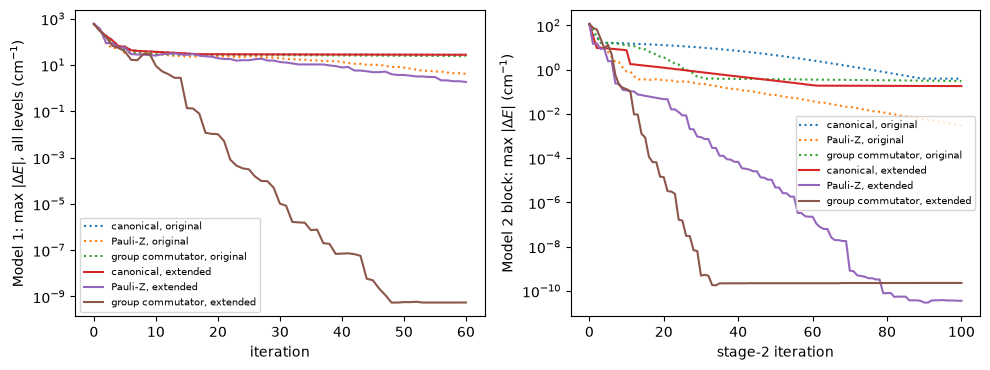

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for (grid, method), r in results["model1"].items():
    axes[0].semilogy(r["every"], ls="-" if grid == "extended" else ":", label=f"{method}, {grid}")
axes[0].set_xlabel("iteration"); axes[0].set_ylabel("Model 1: max $|\\Delta E|$, all levels (cm$^{-1}$)")
for (grid, method), r in results["model2_stage2"].items():
    axes[1].semilogy(r["error"], ls="-" if grid == "extended" else ":", label=f"{method}, {grid}")
axes[1].set_xlabel("stage-2 iteration"); axes[1].set_ylabel("Model 2 block: max $|\\Delta E|$ (cm$^{-1}$)")
for ax in axes:
    ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig("pdfs_figures/duration_grid_recheck.pdf")
plt.show()
with open("simulation_results/duration_grid_recheck.pickle", "wb") as file:
    pickle.dump(results, file)

#### Conclusions

- **The original-grid rows reproduce** `Example_2` and `Example_5` (iteration counts, pair metrics, stage-2 errors), so the comparison is like for like.
- **Model 1:** with durations up to $10^2$ the group commutator brings all seven levels within 1 cm$^{-1}$ in 15 iterations and resolves the 94 cm$^{-1}$ pair exactly; on the original grid the pair stayed 48 cm$^{-1}$ off after 60. Pauli-Z also improves (32 → 23 iterations for $^2F_{5/2}$); the canonical bracket does not use longer durations and is unchanged.
- **Model 2, stage 2:** with durations up to $10^3$ the group commutator reaches 0.01 cm$^{-1}$ in 12 iterations and Pauli-Z in 25. On the original grid Pauli-Z needed 82 and the group commutator stalled at 0.31 cm$^{-1}$.
- **DB-DOI:** for Model 1 the ground doublet reaches $1-F<10^{-2}$ after 2 steps instead of 6 (4 oracle calls instead of 364; the cost of longer evolutions per call is in `Example_15`). For Model 2 the energy improves (72 against 98 cm$^{-1}$ after 5 steps) but the ground-doublet weight stays near 6 %, and two durations sit at the grid edge.
- The earlier conclusions that the closest pair (Model 1), the crystal-field scale (Model 2) and the same-irrep coupling (Model 2, stage 2) limit DBQA were limits of the duration grids. `RESULTS_Model_1.md` §7 and `RESULTS_Model_2.md` §8 record the corrections.